<a href="https://colab.research.google.com/github/ahttpsage/neural-networks-colab/blob/main/regression1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
base_path = "/content/drive/MyDrive/data_resource"
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
# base_path = "/content/drive/MyDrive/data_resource"

Mounted at /content/drive


In [9]:
#!figsize and dpi
#!subplot
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import time
import string

import seaborn as sns
%matplotlib inline
#!numpy,matplotlib,pandas and seaborn



#!cuffkins and plotly


import cufflinks as cf
from plotly.offline import download_plotlyjs,init_notebook_mode,plot,iplot
init_notebook_mode(connected=True)#!connects to interactive js
import plotly.express as px
cf.go_offline()

#!sk learn
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report,confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sqlalchemy import create_engine

from sklearn.decomposition import PCA
#nlp
import pickle
import nltk
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfTransformer,TfidfVectorizer
from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import CountVectorizer
from nltk.stem import WordNetLemmatizer
from nltk.stem import PorterStemmer
from nltk.corpus import wordnet
from nltk.corpus import stopwords

#tensorflow
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Dropout,Input
from tensorflow.keras.models import load_model
from tensorflow.keras.callbacks import EarlyStopping,TensorBoard
from tensorflow.keras.datasets import mnist
#mode metric =>auto min max,loss accuracy etc

from datetime import datetime
from sklearn.compose import ColumnTransformer



In [10]:

cardataDF=pd.read_csv(f"{base_path}/car_price_dataset.csv")

In [11]:
cardataDF

,Brand,Model,Year,Engine_Size,Fuel_Type,Transmission,Mileage,Doors,Owner_Count,Price
0,Kia,Rio,2020,4.2,Diesel,Manual,289944,3,5,8501
1,Chevrolet,Malibu,2012,2.0,Hybrid,Automatic,5356,2,3,12092
2,Mercedes,GLA,2020,4.2,Diesel,Automatic,231440,4,2,11171
3,Audi,Q5,2023,2.0,Electric,Manual,160971,2,1,11780
4,Volkswagen,Golf,2003,2.6,Hybrid,Semi-Automatic,286618,3,3,2867
...,...,...,...,...,...,...,...,...,...,...
9995,Kia,Optima,2004,3.7,Diesel,Semi-Automatic,5794,2,4,8884
9996,Chevrolet,Impala,2002,1.4,Electric,Automatic,168000,2,1,6240
9997,BMW,3 Series,2010,3.0,Petrol,Automatic,86664,5,1,9866
9998,Ford,Explorer,2002,1.4,Hybrid,Automatic,225772,4,1,4084


In [12]:
cardataDF['Brand'].value_counts()

,count
Brand,
Ford,1048
Audi,1038
Volkswagen,1020
Honda,1009
Chevrolet,1003
BMW,999
Hyundai,995
Kia,976
Toyota,970


In [13]:
cardataDF['Transmission'].value_counts()

,count
Transmission,
Manual,3372
Automatic,3317
Semi-Automatic,3311


In [14]:
cardataDF['Model'].value_counts()

,count
Model,
Accord,365
Fiesta,363
Impala,355
5 Series,353
Tiguan,352
Focus,351
Q5,350
A4,350
Elantra,347


In [15]:
cardataDF['Transmission'].nunique()

3

In [16]:
cardataDF['Model'].nunique()

30

In [17]:
cardataDF['Brand'].nunique()

10

In [23]:
obj_cols=cardataDF.select_dtypes(include=np.object_).columns.to_list()
obj_cols

['Brand', 'Model', 'Fuel_Type', 'Transmission']

In [25]:
car_df_obj_df=pd.get_dummies(cardataDF[obj_cols],drop_first=True).astype(int)
car_df_obj_df

,Brand_BMW,Brand_Chevrolet,Brand_Ford,Brand_Honda,Brand_Hyundai,Brand_Kia,Brand_Mercedes,Brand_Toyota,Brand_Volkswagen,Model_5 Series,...,Model_Sonata,Model_Sportage,Model_Tiguan,Model_Tucson,Model_X5,Fuel_Type_Electric,Fuel_Type_Hybrid,Fuel_Type_Petrol,Transmission_Manual,Transmission_Semi-Automatic
0,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
2,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,1,0
4,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
9996,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
9997,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
9998,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0


In [28]:
carDFUpdated=pd.concat(
    objs=[cardataDF.drop(columns=obj_cols).reset_index(),car_df_obj_df.reset_index()
    ],axis=1
)

In [31]:
carDFUpdated['Price']

,Price
0,8501
1,12092
2,11171
3,11780
4,2867
...,...
9995,8884
9996,6240
9997,9866
9998,4084


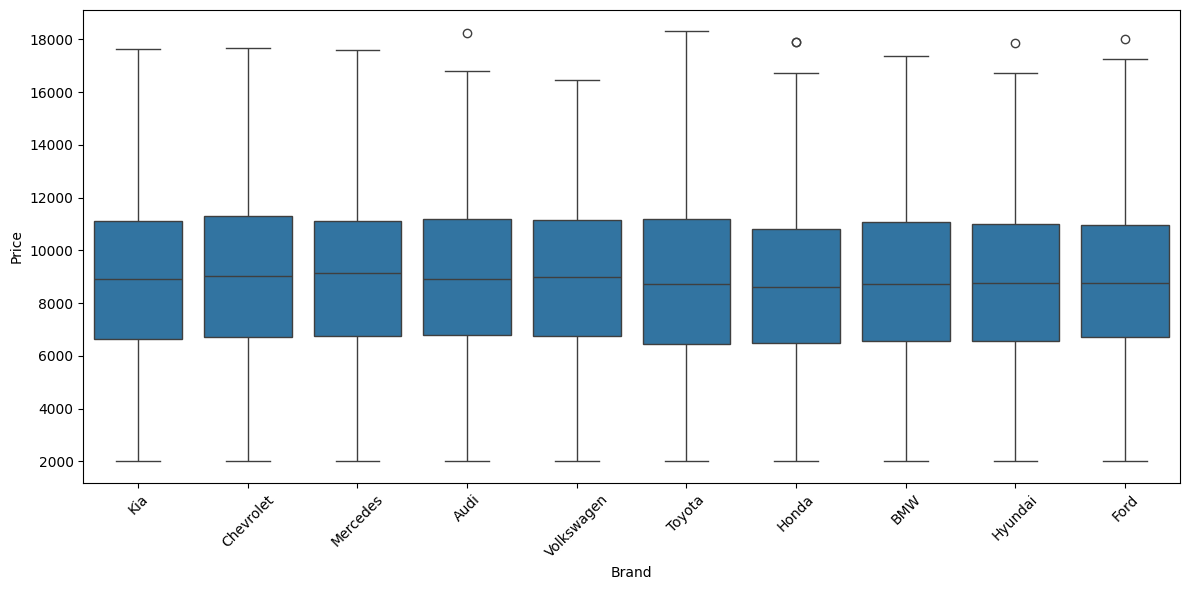

In [38]:
plt.figure(figsize=(12, 6))   # (width, height) in inches
sns.boxplot(data=cardataDF, x="Brand", y="Price")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

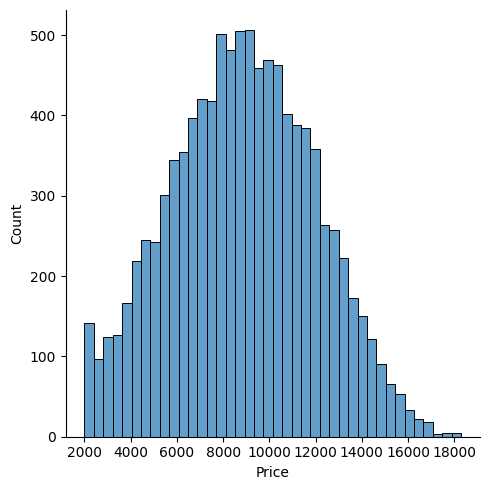

In [43]:

sns.displot(cardataDF['Price'],alpha=0.7)

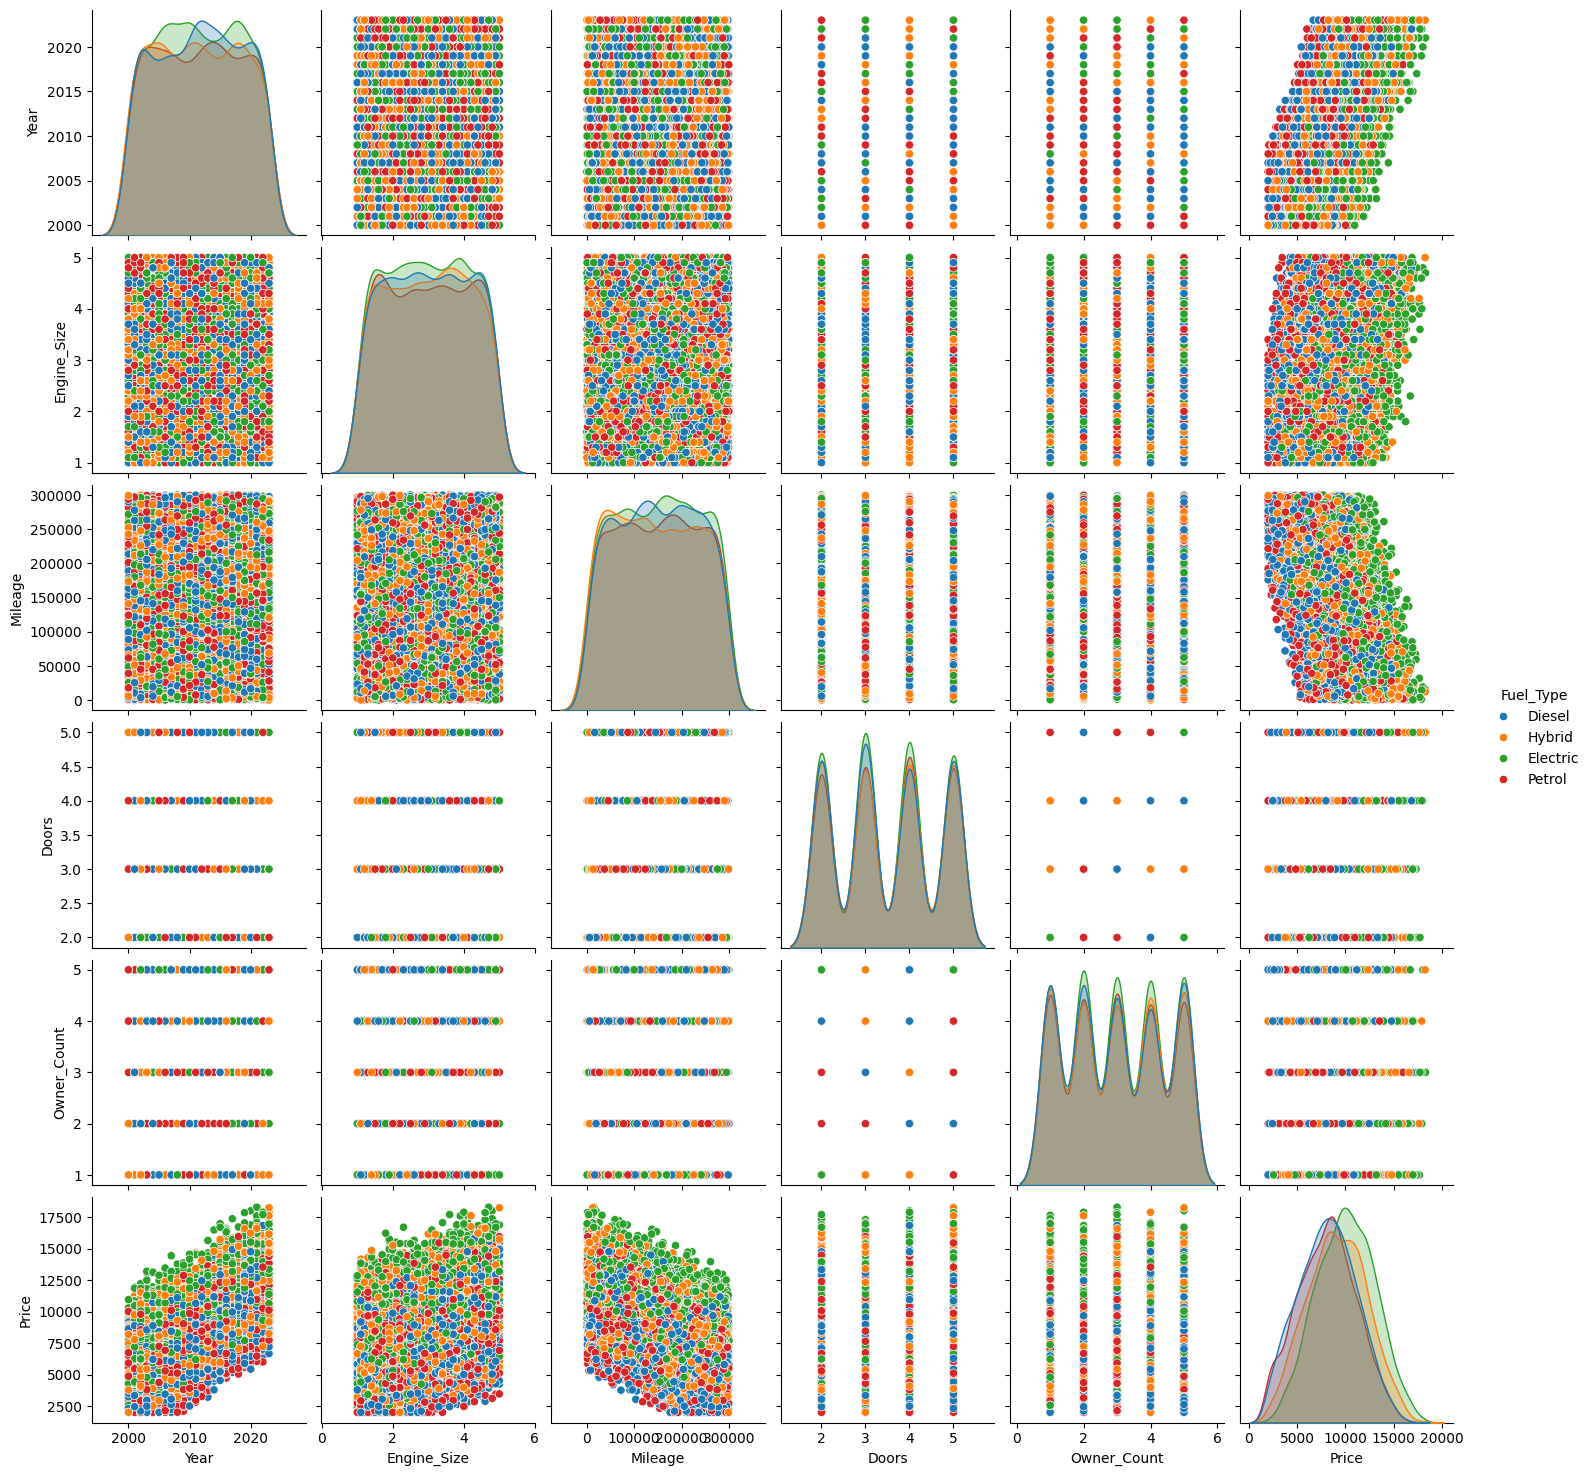

In [44]:
sns.pairplot(data=cardataDF,hue="Fuel_Type")

<Axes: >

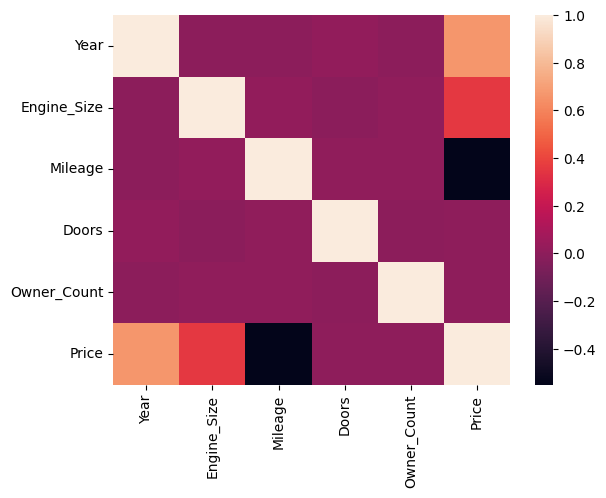

In [45]:
sns.heatmap(cardataDF.select_dtypes(include=np.number).corr())

<Axes: ylabel='Price'>

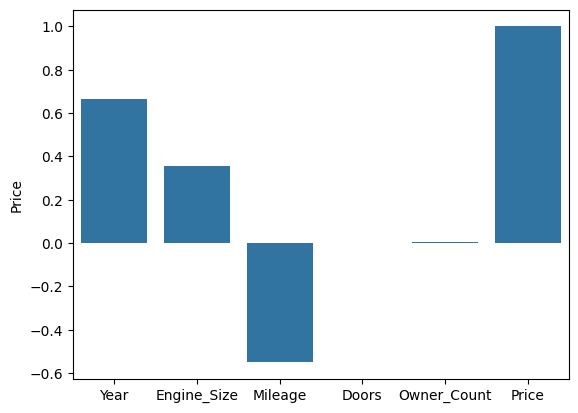

In [46]:
sns.barplot(cardataDF.select_dtypes(include=np.number).corr()['Price'])

In [49]:
carDFUpdated.isna()

,index,Year,Engine_Size,Mileage,Doors,Owner_Count,Price,index,Brand_BMW,Brand_Chevrolet,...,Model_Sonata,Model_Sportage,Model_Tiguan,Model_Tucson,Model_X5,Fuel_Type_Electric,Fuel_Type_Hybrid,Fuel_Type_Petrol,Transmission_Manual,Transmission_Semi-Automatic
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9996,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9997,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9998,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [50]:
X=carDFUpdated.drop('Price',axis=1)

In [51]:
X

,index,Year,Engine_Size,Mileage,Doors,Owner_Count,index,Brand_BMW,Brand_Chevrolet,Brand_Ford,...,Model_Sonata,Model_Sportage,Model_Tiguan,Model_Tucson,Model_X5,Fuel_Type_Electric,Fuel_Type_Hybrid,Fuel_Type_Petrol,Transmission_Manual,Transmission_Semi-Automatic
0,0,2020,4.2,289944,3,5,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,1,2012,2.0,5356,2,3,1,0,1,0,...,0,0,0,0,0,0,1,0,0,0
2,2,2020,4.2,231440,4,2,2,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,3,2023,2.0,160971,2,1,3,0,0,0,...,0,0,0,0,0,1,0,0,1,0
4,4,2003,2.6,286618,3,3,4,0,0,0,...,0,0,0,0,0,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,2004,3.7,5794,2,4,9995,0,0,0,...,0,0,0,0,0,0,0,0,0,1
9996,9996,2002,1.4,168000,2,1,9996,0,1,0,...,0,0,0,0,0,1,0,0,0,0
9997,9997,2010,3.0,86664,5,1,9997,1,0,0,...,0,0,0,0,0,0,0,1,0,0
9998,9998,2002,1.4,225772,4,1,9998,0,0,1,...,0,0,0,0,0,0,1,0,0,0


In [52]:
Y=carDFUpdated['Price']

In [53]:
X=X.values

In [54]:
Y=Y.values

In [55]:
from sklearn.preprocessing import  MinMaxScaler

In [56]:
minmax_m=MinMaxScaler()

In [57]:
X

array([[0.000e+00, 2.020e+03, 4.200e+00, ..., 0.000e+00, 1.000e+00,
        0.000e+00],
       [1.000e+00, 2.012e+03, 2.000e+00, ..., 0.000e+00, 0.000e+00,
        0.000e+00],
       [2.000e+00, 2.020e+03, 4.200e+00, ..., 0.000e+00, 0.000e+00,
        0.000e+00],
       ...,
       [9.997e+03, 2.010e+03, 3.000e+00, ..., 1.000e+00, 0.000e+00,
        0.000e+00],
       [9.998e+03, 2.002e+03, 1.400e+00, ..., 0.000e+00, 0.000e+00,
        0.000e+00],
       [9.999e+03, 2.001e+03, 2.100e+00, ..., 0.000e+00, 1.000e+00,
        0.000e+00]])

In [58]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y)

In [59]:
X_train_s=minmax_m.fit_transform(X_train)

In [60]:
X_test_s=minmax_m.transform(X_test)

In [68]:
car_Reg_Model=Sequential()

In [69]:
X.shape

(10000, 50)

In [70]:
car_Reg_Model.add(Dense(units=50,activation="relu"))
car_Reg_Model.add(Dropout(0.2))

In [71]:
car_Reg_Model.add(Dense(units=40,activation="relu"))
car_Reg_Model.add(Dropout(0.2))

In [72]:
car_Reg_Model.add(Dense(units=20,activation="relu"))
car_Reg_Model.add(Dropout(0.2))

In [73]:
car_Reg_Model.add(Dense(units=1,activation="relu"))

In [75]:
car_Reg_Model.compile(
    optimizer="adam",
    loss="mse"   # or "mean_squared_error"
)


In [76]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=25,
    restore_best_weights=True,
    verbose=1
)


In [77]:
car_Reg_Model.fit(
    x=X_train_s,
    y=Y_train,
    validation_data=(X_test_s, Y_test),
    epochs=30,
    batch_size=256,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - loss: 88353080.0000 - val_loss: 87366848.0000
Epoch 2/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 88823368.0000 - val_loss: 87228256.0000
Epoch 3/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 88253272.0000 - val_loss: 86483912.0000
Epoch 4/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 86025464.0000 - val_loss: 83804224.0000
Epoch 5/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 83924704.0000 - val_loss: 76772400.0000
Epoch 6/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 74076608.0000 - val_loss: 62545292.0000
Epoch 7/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 57856276.0000 - val_loss: 41403952.0000
Epoch 8/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 36873116.0000 - val_loss: 20938520.0000
Epoch 9/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 19379288.0000 - val_loss: 11733218.0000
Epoch 10/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 14166839.0000 - val_loss: 10475285.0000
Epoch 11/30
30/30

In [78]:
error_df=pd.DataFrame(car_Reg_Model.history.history)

<Axes: >

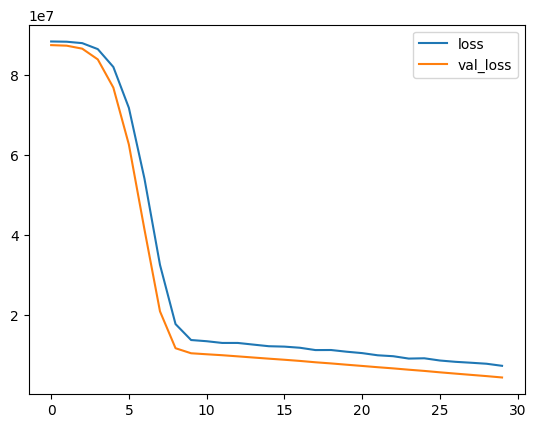

In [79]:
error_df.plot()

In [80]:
pred1=car_Reg_Model.predict(X_test_s)

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [81]:
print(metrics.root_mean_squared_error(pred1,Y_test))

2105.167724609375


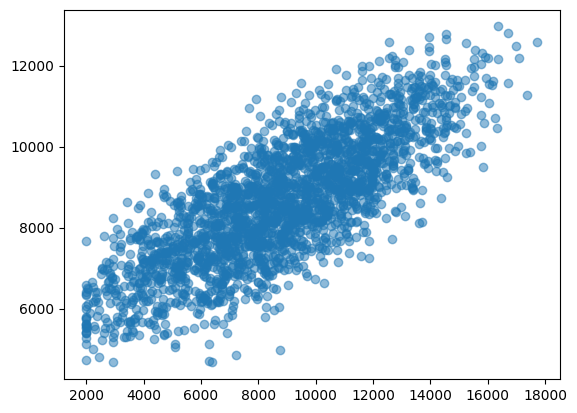

In [83]:
plt.scatter(Y_test,pred1,alpha=0.5)

In [84]:
car_Reg_Model.save("/content/drive/MyDrive/car.keras")